In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline 
np.set_printoptions(precision=4, suppress=True)


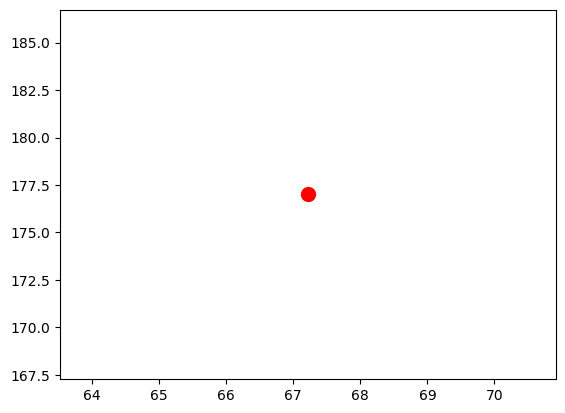

In [4]:
x = np.array([66,  68, 60,   70,  65,  61,  74,  73,  75,  67,  60,  61,  64,    77])
y = np.array([160, 170, 110, 178, 155, 120, 233, 243, 255, 164, 155,  170, 165, 200])
ave_x = np.average(x)
ave_y = np.average(y)
#plot data
plt.figure()
plt.scatter(ave_x,ave_y, s=100, c="red")
plt.show()


## Models

Here we consider four different models:
$$
m_1(x_i;\theta) = \theta_0+\theta_1 x_i 
$$
$$
m_2(x_i;\theta) = \theta_0+\theta_1 x_i +\theta_2 x_i^2  
$$
$$
m_3(x_i;\theta) = \theta_0+\theta_1 x_i +\theta_2 x_i^2 +\theta_3 x_i^3
$$
$$
m_4(x_i;\theta) = \theta_0+\theta_1 x_i +\theta_2 x_i^2 +\theta_3 x_i^3 +\theta_4 x_i^4
$$

These models can all be written as $X\theta$, but the size of $X$ and $\theta$ and their structure will be different.

In [52]:
# Lets consider four different models
Xones = np.ones(shape=(len(x)))
X1 = np.c_[Xones[:],x]
X2 = np.c_[Xones[:],x,x**2]
X3 = np.c_[Xones[:],x,x**2,x**3]
X4 = np.c_[Xones[:],x,x**2,x**3,x**4]


### We can solve each of these by using the normal equations

In [53]:
theta_1 = np.linalg.inv(X1.T@X1)@(X1.T@y)
theta_2 = np.linalg.inv(X2.T@X2)@(X2.T@y)
theta_3 = np.linalg.inv(X3.T@X3)@(X3.T@y)
theta_4 = np.linalg.inv(X4.T@X4)@(X4.T@y)

In [54]:
print(f"Linear parameters: {theta_1}\n")
print(f"Quadratic parameters: {theta_2}\n")
print(f"Cubic parameters: {theta_3}\n")
print(f"Quartic parameters: {theta_4}\n")

Linear parameters: [-239.6352    6.1986]

Quadratic parameters: [-113.7148    2.467     0.0275]

Cubic parameters: [28405.0895 -1265.1112    18.7342    -0.0917]

Quartic parameters: [-560548.1292   33330.6224    -741.2889       7.3094      -0.027 ]



### Now we can also look at the fits to data

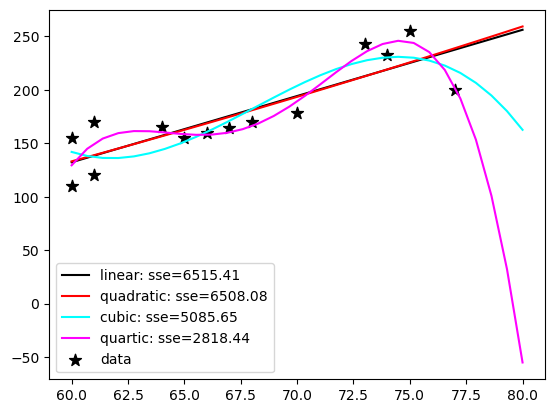

In [55]:
x_plot = np.linspace(60,80,30)
Xones_plot = np.ones(shape=(len(x_plot)))
X1_plot = np.c_[Xones_plot[:],x_plot]
X2_plot = np.c_[Xones_plot[:],x_plot,x_plot**2]
X3_plot = np.c_[Xones_plot[:],x_plot,x_plot**2,x_plot**3]
X4_plot = np.c_[Xones_plot[:],x_plot,x_plot**2,x_plot**3,x_plot**4]

sse1 = np.sum((y-X1@theta_1)**2)
sse2 = np.sum((y-X2@theta_2)**2)
sse3 = np.sum((y-X3@theta_3)**2)
sse4 = np.sum((y-X4@theta_4)**2)

plt.plot(x_plot,X1_plot@theta_1,color='black',label=f'linear: sse={sse1:.2f}')
plt.plot(x_plot,X2_plot@theta_2,color='red',label=f'quadratic: sse={sse2:.2f}')
plt.plot(x_plot,X3_plot@theta_3,color='cyan',label=f'cubic: sse={sse3:.2f}')
plt.plot(x_plot,X4_plot@theta_4,color='magenta',label=f'quartic: sse={sse4:.2f}')
plt.scatter(x,y, s=80, c="black",label='data',marker='*')
plt.legend()
plt.show()